### what is statistical analysis ?
* it is science of collecting,exploring, and presenting data to discover underlying pattern and trends.
    * describes data characteristics.
    * test hypotheses about population.
    * quantifies relationships between variables.
    * provides framework for making evidence based decisions.
### why statistical analysis ?
* extract meaningful insights from raw data.
* make data driven decision with confidence.
* quantify uncertainty in your findings.
* validate hypotheses and assumptinos.
* communication results effectively.

### types of statistical methods 
* descriptive statistics
    * summarize and describe data characteristics.
* inferential statistics
    * draw conclusion about population from samples.
* predictive statistics
    * use current and historical data to predict future outcome.

### parametric vs non parametric test
* parametrics test
    * normal distribution and other specific conditions.
    * more powerful when assumptions are met.
    * eg- t-test, ANOVA , pearson correlation.
* non parametrics test  
    * make fewer assumptions about the data distribution.
    * often use ranks rather than actual values.
    * eg- mann whitney U, kruskal wallis, spearman correlation.


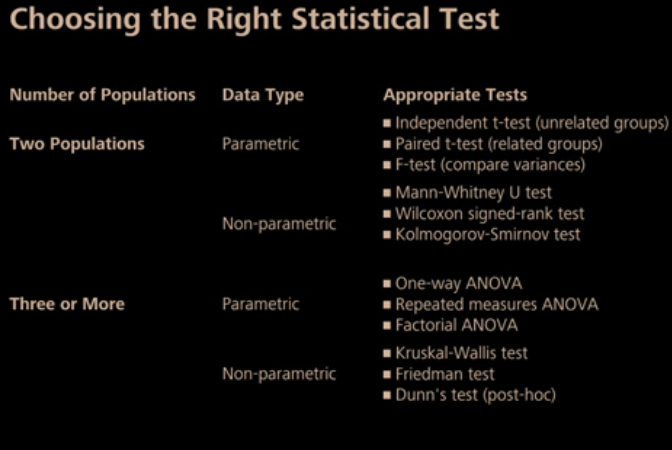

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# add from url
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
heart_data=pd.read_csv(url, names=column_names,na_values='?')
heart_data

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,45.0,1.0,1.0,110.0,264.0,0.0,0.0,132.0,0.0,1.2,2.0,0.0,7.0,1
299,68.0,1.0,4.0,144.0,193.0,1.0,0.0,141.0,0.0,3.4,2.0,2.0,7.0,2
300,57.0,1.0,4.0,130.0,131.0,0.0,0.0,115.0,1.0,1.2,2.0,1.0,7.0,3
301,57.0,0.0,2.0,130.0,236.0,0.0,2.0,174.0,0.0,0.0,2.0,1.0,3.0,1


In [3]:
heart_data.info() #dataset info

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [4]:
#missing values
heart_data.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [5]:
# replace missing values with median for numerical columns
heart_data=heart_data.fillna(heart_data.median())

#### Understanding the describe() function
The describe() function provides a quick statistical summary of your data:

* count: Number of non-missing values for each variable
* mean: The average value (sum of all values divided by count)
* std: Standard deviation, which measures how spread out the values are from the mean
* min: The minimum (smallest) value in the dataset
* 25%: The first quartile (Q1) - 25% of values fall below this number
* 50%: The median or second quartile (Q2) - the middle value when ordered
* 75%: The third quartile (Q3) - 75% of values fall below this number
* max: The maximum (largest) value in the dataset


* The interquartile range (IQR) is Q3-Q1, representing the middle 50% of the data.

In [6]:
heart_data.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.663366,4.722772,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.934375,1.938383,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


In [7]:
# Set visualization style
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12

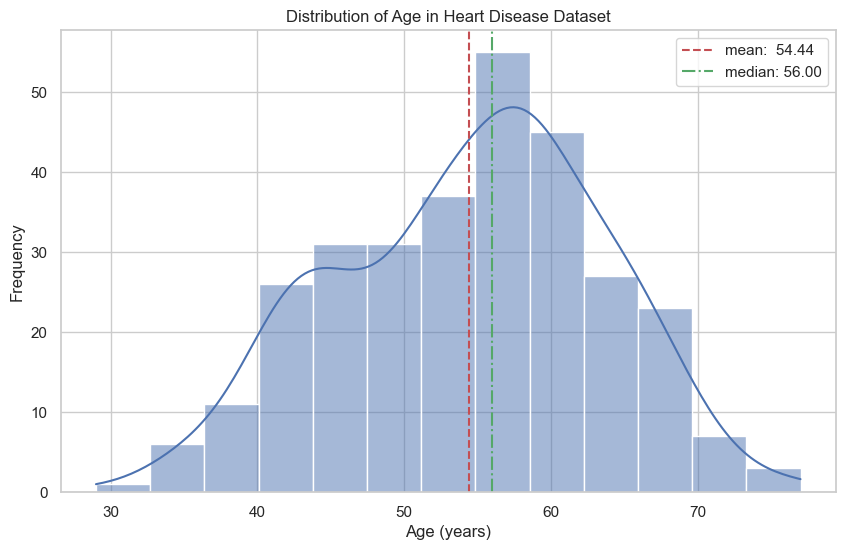

In [8]:
#convert target variable to binary .
heart_data['target']=heart_data['target'].apply(lambda x: 0 if x==0 else 1)

#convert sex to categorical for better interpretability
heart_data['sex']=heart_data['sex'].map({0:'Female',1:'Male'})

plt.figure(figsize=(10,6))
sns.histplot(heart_data['age'],kde=True)
plt.title('Distribution of Age in Heart Disease Dataset')
plt.xlabel('Age (years)')
plt.ylabel('Frequency')
plt.axvline(heart_data['age'].mean(),color='r',linestyle='--',
            label=f'mean: {heart_data["age"].mean(): .2f}')
plt.axvline(heart_data['age'].median(),color='g',linestyle='-.',
            label=f'median: {heart_data["age"].median():.2f}')
plt.legend()
plt.show()

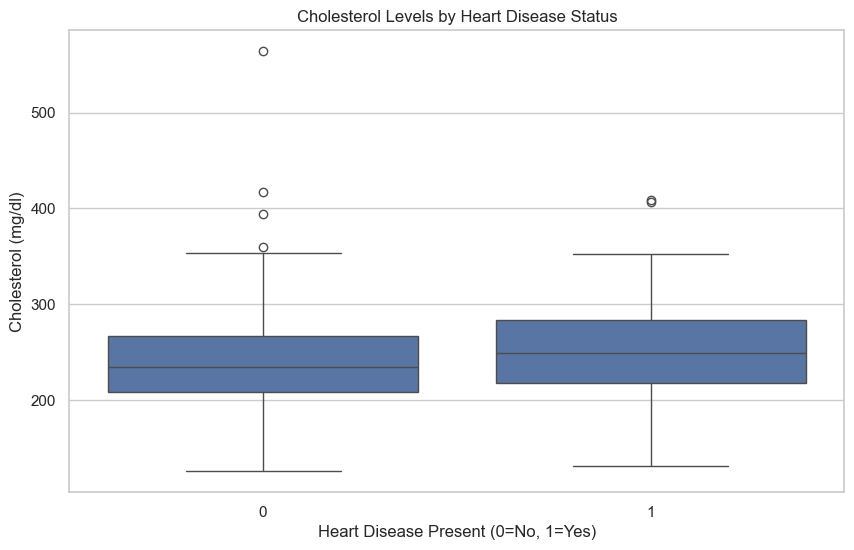

In [9]:
#box plot
plt.figure(figsize=(10,6))
sns.boxplot(x="target",y='chol',data=heart_data)
plt.title('Cholesterol Levels by Heart Disease Status')
plt.xlabel('Heart Disease Present (0=No, 1=Yes)')
plt.ylabel('Cholesterol (mg/dl)')
plt.show()

In [10]:
print(heart_data[['sex', 'target']].value_counts())
print(heart_data[['sex', 'target']].dtypes)

sex     target
Male    1         114
        0          92
Female  0          72
        1          25
Name: count, dtype: int64
sex       object
target     int64
dtype: object


In [11]:
heart_data['sex'] = heart_data['sex'].astype(str)
heart_data['target'] = heart_data['target'].astype(str)

In [12]:
heart_data[['sex', 'target']].isna().sum()

sex       0
target    0
dtype: int64

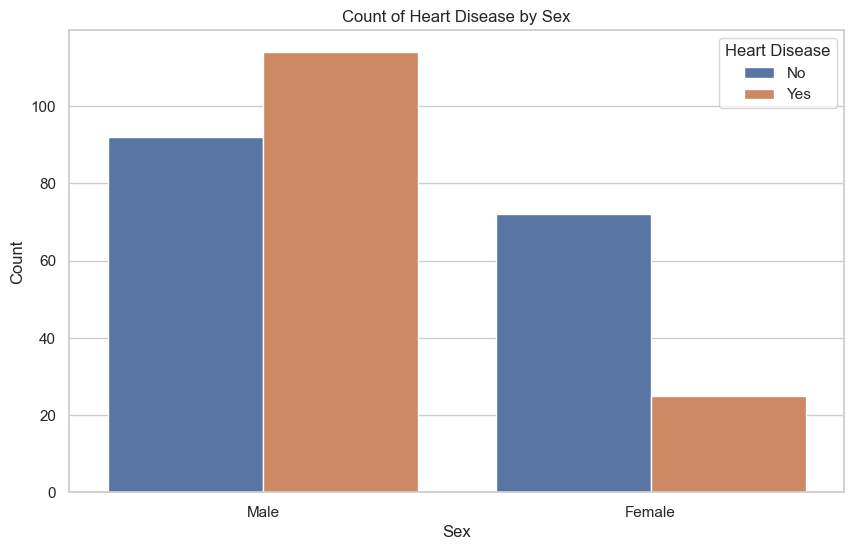

In [13]:
#count plot- (how manu are in each category?)
plt.figure(figsize=(10, 6))
sns.countplot(x='sex',hue='target',data=heart_data)
plt.title('Count of Heart Disease by Sex')
plt.xlabel('Sex')
plt.ylabel('Count')
plt.legend(title='Heart Disease', labels=['No', 'Yes'])
plt.show()
     

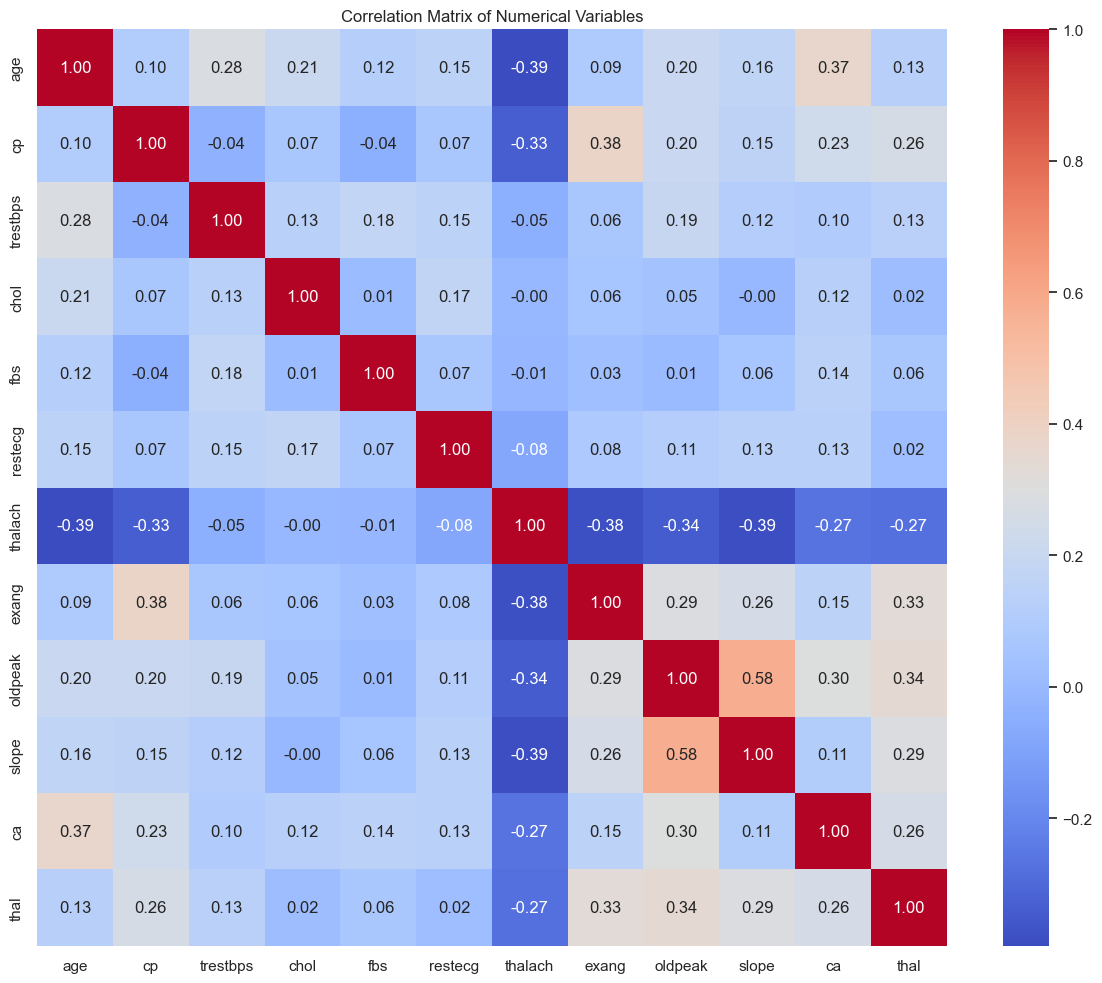

In [14]:
# correlation heatmap for numerical variables
plt.figure(figsize=(12,10))
numerical_cols=heart_data.select_dtypes(include=['float64','int64']).columns
correlation_matrix=heart_data[numerical_cols].corr()
sns.heatmap(correlation_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()